# ***`Table of Contents`***

1.   Project Review and Aims.
2.   Privacy, Ethics and Risk Management
3.   Environment Setup and Imports
4.   Data Loading and Exploratory Data Analysis (EDA).
5.   Privacy and Toxic Filtering.
6.   Model Training.
7.   Fairness & Bias Checks: Demographic Parity and Equal Opportunities.
8.   Explainability
9.   Risk Controls for Neural Network (MLP) Model
10.  Comprehensive Risk Analysis and Management Plan
11.  Model Card
12.  Red Team - Attack & Defense Playbook
13.  Embedding XAI in the Risk Modeling Lifecycle



# ***`1. Project Review and Aims`***

**Project Review**

This project focused on developing a credit risk classification system using customer financial and behavioral data. The target variable was a synthetic credit risk indicator (High vs. Low Risk), derived from utilization, balance, and inactivity features. A Neural Network (MLP) model was chosen for its ability to model non-linear patterns; interpretability is added post hoc with SHAP and LIME.

**Throughout development:**

* Data preprocessing handled missing values, categorical encoding, and normalization.

* Bias and fairness checks (Demographic Parity, Equal Opportunity) were applied to detect disparities across education levels.

* Explainable AI tools (LIME, SHAP) were used to interpret both global and local model behavior.

* Risk management included adversarial robustness testing, privacy-preserving techniques, and monitoring strategies.

* The first version reached 99.9% accuracy, but that was caused by target leakage. The audited, leakage-free results (feature set C) are reported in section 6 and in the model card (section 11).



**Project Aims**

1. Accurate Risk Prediction

    * Classify customers into high- and low-risk groups with high precision and recall.

2. Fair and Transparent Decisions

    * Ensure predictions are free from unjust bias and provide interpretable explanations to stakeholders.

3. Robustness and Reliability

    * Incorporate privacy safeguards, adversarial testing, and monitoring mechanisms to ensure long-term stability.

4. Support Responsible Lending

    * Provide financial institutions with a trustworthy tool for assessing creditworthiness while protecting customers’ rights and interests.

# ***`2. Ethics, Governance, and Compliance in Credit Scoring AI`***

**1. Introduction / Context**

*  Purpose of the project: building a responsible AI-based credit scoring system.

*  Importance: High-risk AI due to financial decisions and customer rights.


**2. Stakeholders**

*2.1 Direct Stakeholders*

* Bank / Credit Department Management → Use scores for credit decisions and retention strategies.

* Marketing & Customer Relationship Teams → Targeted campaigns based on creditworthiness.

* Data Science / Analytics Teams → Build, train, validate, and maintain models.

* Product Development Teams → Inform financial product design.

* Customer Service Teams → Communicate credit decisions to customers.

*2.2 Indirect Stakeholders*

* Customers → Affected by fairness, accuracy, and transparency of scores.

* Shareholders / Investors → Benefit from reduced credit risk and improved financial performance.

* Regulators / Compliance Bodies → Ensure fair lending, privacy, and legal compliance.

2.3 Stakeholder Map


Stakeholder Map


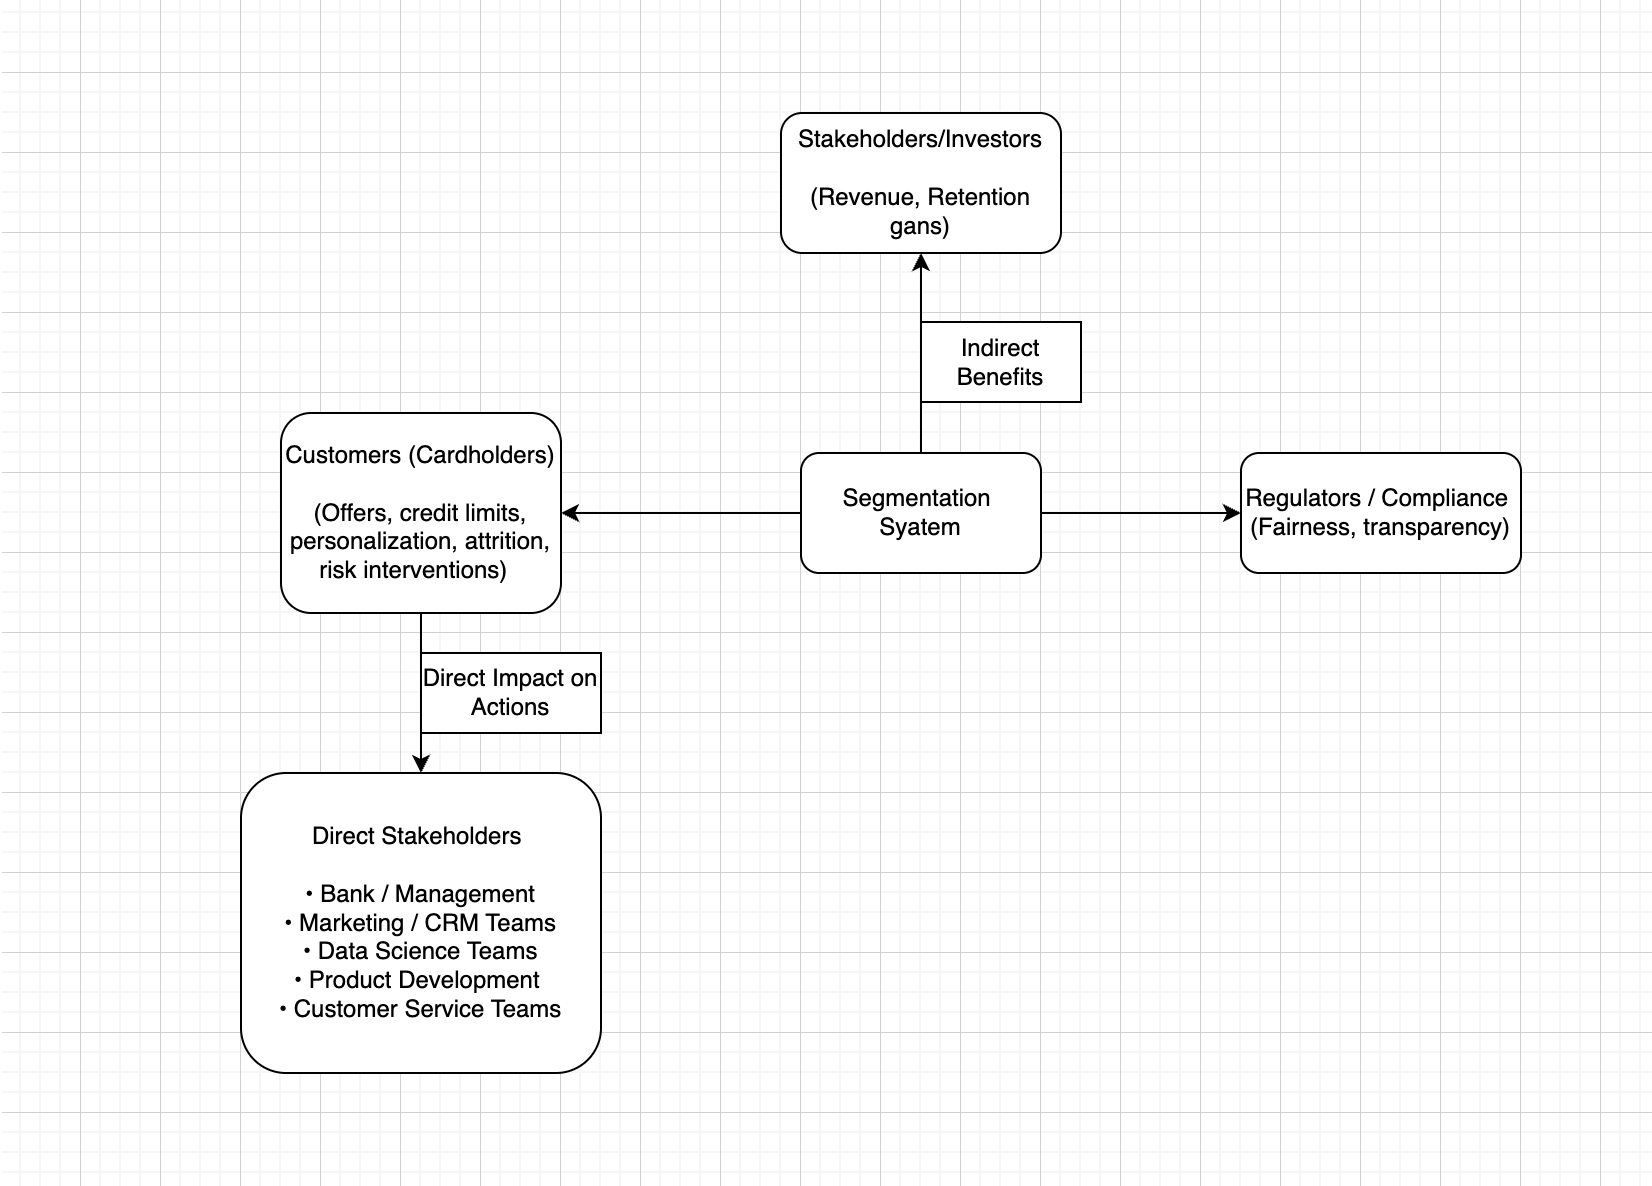

In [1]:
from IPython.display import Image, display

image_path = "/Users/aikyask/Desktop/git/responsible-ai-credit-risk/stakeholder_map.png"
print("Stakeholder Map")
display(Image(filename=image_path))


**3. Value-Based Engineering (VBE) Principles**

* Ecosystem Responsibility: Collaborate with internal teams to ensure high-quality, representative data.

* Stakeholder Inclusiveness: Include customer, regulatory, and management perspectives when defining model requirements.

* Context Sensitivity & Laws: Respect local lending regulations and consumer protection laws.

* Transparency & Risk Analysis: Document model design and assess ethical risks (bias, discrimination).

* Leadership Engagement: Embed ethical KPIs alongside financial ones.

**4. Motivation for AI Regulation**

* Fairness & Non-Discrimination: Prevent biased credit scoring based on sensitive demographics.

* Transparency & Explainability: Ensure customers and regulators can understand model decisions.

* Privacy & Data Protection: Protect financial and demographic data under GDPR/CCPA.

* Accountability & Oversight: Data teams and bank management responsible for errors.

* Trust & Consumer Protection: Avoid manipulative targeting or unfair credit denial.

* Market Stability: Accurate scoring prevents systemic financial risk.

**5. Regulatory Compliance**

*5.1 Primary Approaches*

* Risk-based, sector-specific, and principle-based (fairness, transparency, trust).

*5.2 EU AI Act Compliance (High-Risk AI)*

* Data Quality & Governance (Arts. 9–10): Representative, bias-checked datasets; documented preprocessing.

* Technical Documentation (Art. 11): Algorithms, features, assumptions, and decision logic.

* Recordkeeping (Art. 12): Logs of predictions, updates, and decisions.

* Transparency (Art. 13): Explainable outputs to customers and regulators.

* Human Oversight (Art. 14): Staff review/override capability.

* Accuracy, Robustness, Cybersecurity (Art. 15): Monitor performance and defend against attacks.

* Quality Management System (Art. 17): Formal processes for monitoring and continuous improvement.

* Registration & Market Surveillance (Arts. 51, 61): Register system; allow audits.

* Incident Reporting (Art. 62): Report errors that affect customers or financial decisions.

**6. Open Challenges & Criticisms**

* Rapid AI evolution vs slow regulation.

* Difficulties in monitoring and enforcement.

* Global AI use vs territorial legal limitations.

* Balancing innovation with strict compliance.

* Ambiguity in defining “high-risk” vs low-impact AI.

* Limited protections for open-source or externally sourced models.

* AI liability and accountability questions.

* **Criticisms:** over-regulation, legal complexity, insufficient consumer protection, global competitiveness issues.

**7. Risk Management & Recommendations**

* Continuous Risk Assessment: Identify bias, misclassification, privacy violations.

* Bias Mitigation & Fairness Controls: Remove/mask sensitive attributes, test subgroup performance.

* Transparency & Explainability: Document and communicate model logic, confidence, and limitations.

* Human Oversight: Enable staff to review or override automated decisions.

* Robustness & Security: Monitor performance, retrain, and defend against adversarial attacks.

* Quality Management & Continuous Improvement: Formal processes for compliance, monitoring, and iterative improvement.

* Reporting & Accountability: Maintain logs, register the system, and report serious incidents.

**Architecture Diagram**

Architecture Diagram


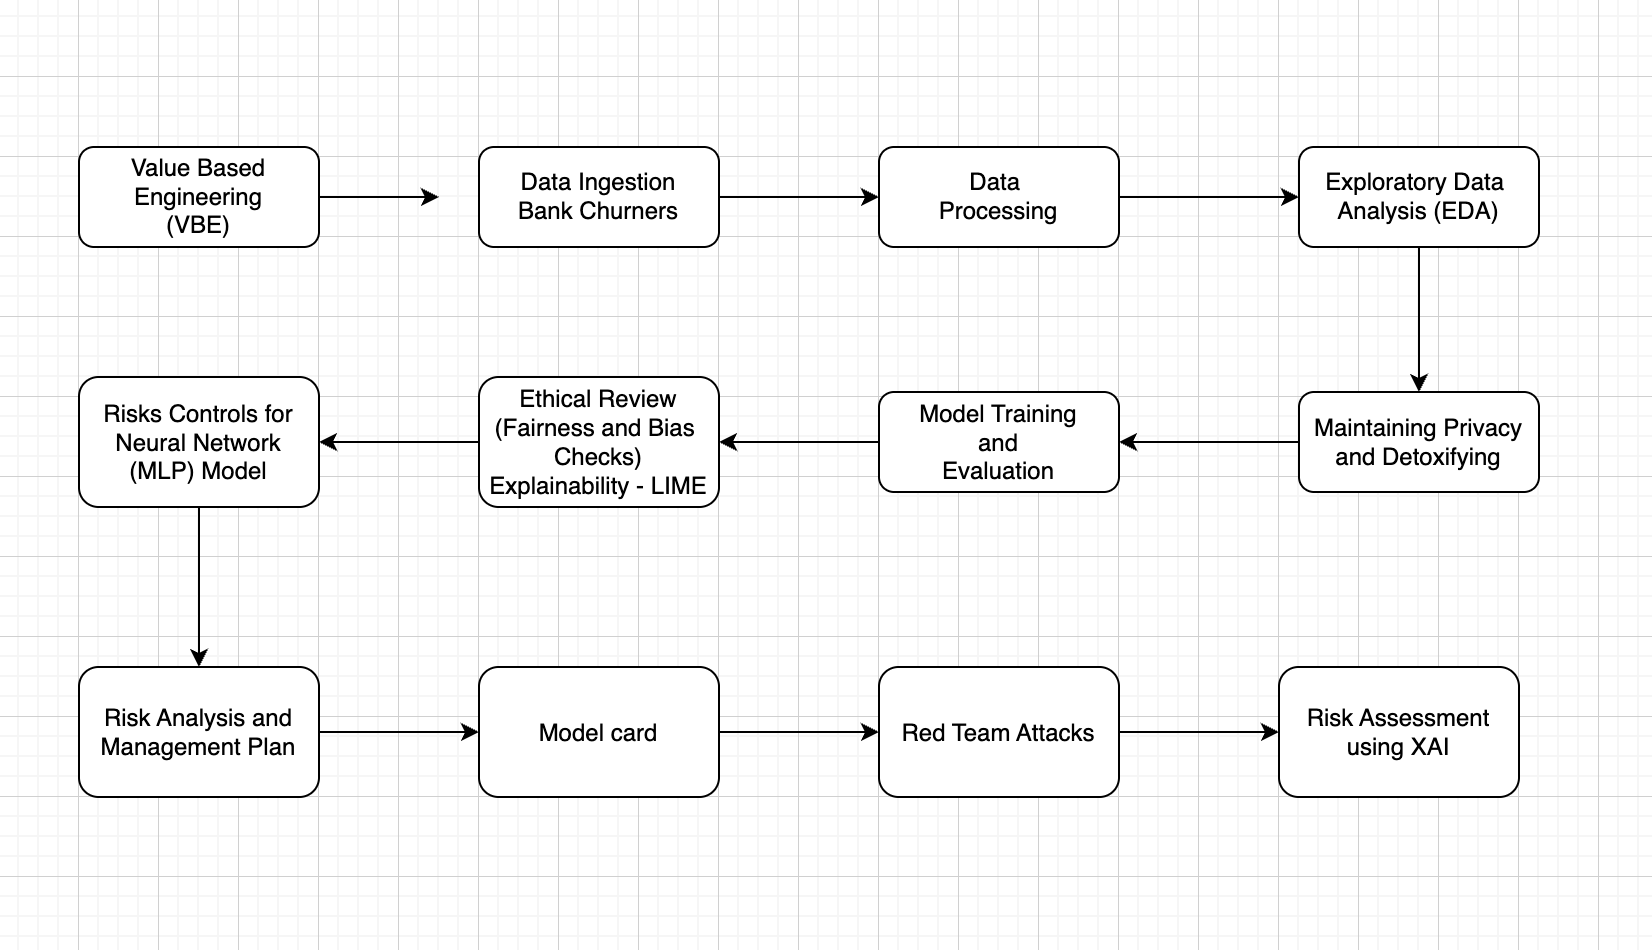

In [2]:
from IPython.display import Image, display

image_path = "/Users/aikyask/Desktop/git/responsible-ai-credit-risk/architecture_diagram.png"
print("Architecture Diagram")
display(Image(filename=image_path))


# ***`3. Environment Setup and Imports`***

**Goal**:  
1. Import core libraries (pandas, numpy, matplotlib, seaborn, sklearn).  
2. Set random seed and display options for reproducibility.   

In [3]:
# Run once. Use %pip (not !pip) so packages go into the environment this notebook is using.
%pip install -q numpy pandas scipy scikit-learn imbalanced-learn matplotlib seaborn tqdm shap lime
# OPTIONAL, only for the Presidio demo in section 5 (skip if it gives trouble; nothing later depends on it):
# %pip install -q presidio-analyzer presidio-anonymizer spacy
# !python -m spacy download en_core_web_lg

Note: you may need to restart the kernel to use updated packages.


In [4]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, recall_score, precision_score, accuracy_score
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
R = {}  # results store: the model card is generated from this at the end of section 12

# ***`4. Loading and Understanding the Dataset`***

**Goal**:  
1. Load the dataset into a pandas DataFrame.  
2. Inspect rows, columns, and data types (`head`, `info`, `dtypes`).  
3. Check for missing values and duplicates.  
4. Get basic statistics (`describe`) to understand numeric distributions.

In [5]:
df = pd.read_csv("/Users/aikyask/Desktop/git/responsible-ai-credit-risk/bank_churners.csv")
print("Loaded Bank Churners Dataset")

Loaded Bank Churners Dataset


In [6]:
print("Displaying first 5 rows")
df.head(5)

Displaying first 5 rows


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [7]:
print("Displaying all non-null columns")
df.info()

Displaying all non-null columns
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                           

In [8]:
print("Describing all columns")
df.describe()

Describing all columns


,CLIENTNUM,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
count,1.012700e+04,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,7.391776e+08,46.325960,2.346203,35.928409,3.812580,2.341167,2.455317,8631.953698,1162.814061,7469.139637,0.759941,4404.086304,64.858695,0.712222,0.274894,0.159997,0.840003
std,3.690378e+07,8.016814,1.298908,7.986416,1.554408,1.010622,1.106225,9088.776650,814.987335,9090.685324,0.219207,3397.129254,23.472570,0.238086,0.275691,0.365301,0.365301
min,7.080821e+08,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000,0.000008,0.000420
25%,7.130368e+08,41.000000,1.000000,31.000000,3.000000,2.000000,2.000000,2555.000000,359.000000,1324.500000,0.631000,2155.500000,45.000000,0.582000,0.023000,0.000099,0.999660
50%,7.179264e+08,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,4549.000000,1276.000000,3474.000000,0.736000,3899.000000,67.000000,0.702000,0.176000,0.000181,0.999820
75%,7.731435e+08,52.000000,3.000000,40.000000,5.000000,3.000000,3.000000,11067.500000,1784.000000,9859.000000,0.859000,4741.000000,81.000000,0.818000,0.503000,0.000337,0.999900
max,8.283431e+08,73.000000,5.000000,56.000000,6.000000,6.000000,6.000000,34516.000000,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.999000,0.999580,0.999990


In [9]:
print("Finding Missing Values")
print(df.isnull().sum())

Finding Missing Values
CLIENTNUM                                                                                                                             0
Attrition_Flag                                                                                                                        0
Customer_Age                                                                                                                          0
Gender                                                                                                                                0
Dependent_count                                                                                                                       0
Education_Level                                                                                                                       0
Marital_Status                                                                                                                        0
Income_Category          

In [10]:
print("Describing Numerical Columns")
num_cols = df.select_dtypes(include=['number']).columns
print(df[num_cols].describe())

Describing Numerical Columns
          CLIENTNUM  Customer_Age  Dependent_count  Months_on_book  \
count  1.012700e+04  10127.000000     10127.000000    10127.000000   
mean   7.391776e+08     46.325960         2.346203       35.928409   
std    3.690378e+07      8.016814         1.298908        7.986416   
min    7.080821e+08     26.000000         0.000000       13.000000   
25%    7.130368e+08     41.000000         1.000000       31.000000   
50%    7.179264e+08     46.000000         2.000000       36.000000   
75%    7.731435e+08     52.000000         3.000000       40.000000   
max    8.283431e+08     73.000000         5.000000       56.000000   

       Total_Relationship_Count  Months_Inactive_12_mon  \
count              10127.000000            10127.000000   
mean                   3.812580                2.341167   
std                    1.554408                1.010622   
min                    1.000000                0.000000   
25%                    3.000000              

In [11]:
print("Describing Categorical Columns")
cat_cols = df.select_dtypes(include=['object']).columns
print(df[cat_cols].describe())

Describing Categorical Columns
           Attrition_Flag Gender Education_Level Marital_Status  \
count               10127  10127           10127          10127   
unique                  2      2               7              4   
top     Existing Customer      F        Graduate        Married   
freq                 8500   5358            3128           4687   

       Income_Category Card_Category  
count            10127         10127  
unique               6             4  
top     Less than $40K          Blue  
freq              3561          9436  


**Dropping the unnecessary columns that do not contribute to the analysis:**

**CLIENTNUM**

Reason: Unique identifier; it carries no predictive value and can raise privacy concerns if stored/used unnecessarily.

**Gender**

Reason: Using gender to predict credit scores is illegal in many jurisdictions (e.g., U.S. Equal Credit Opportunity Act). Including it can lead to biased predictions.

**Marital_Status**

Reason: Often considered protected class data; using it in credit scoring models may be illegal or raise discrimination concerns.

**Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1**

Reason: This is already a derived model output. Using it could leak sensitive information or compound bias.

**Attrition_Flag**

Reason: This is related to customer churn, not directly to creditworthiness. Including it may introduce leakage if churn is affected by credit usage.

In [12]:
print("Dropping unnecessary columns")
df = df.drop(columns=[
    "CLIENTNUM",
    "Gender",
    "Marital_Status",
    "Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1",
    "Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2",
    "Attrition_Flag"
])

Dropping unnecessary columns


# ***Exploratory Data Analysis***

**Goal**:  
1. Explore feature distributions with histograms, boxplots, and counts.  
2. Analyze relationships between variables (correlation heatmap, scatterplots).  
3. Identify trends, outliers, and potential data imbalances.  

**Credit Age**

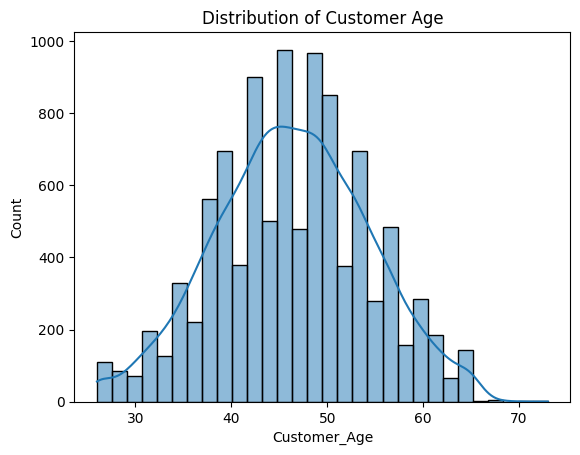

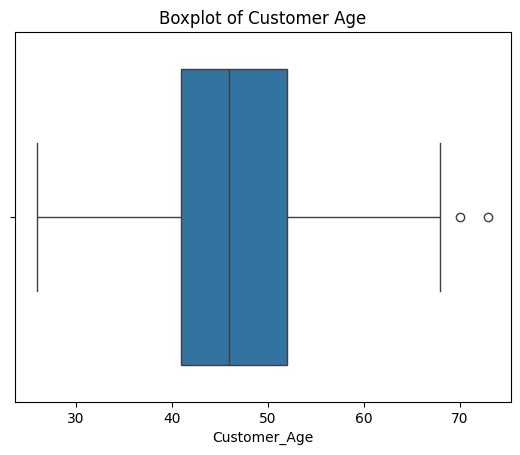

In [13]:
# Distribution of Customer_Age
sns.histplot(df['Customer_Age'], bins=30, kde=True)
plt.title("Distribution of Customer Age")
plt.show()

sns.boxplot(x=df['Customer_Age'])
plt.title("Boxplot of Customer Age")
plt.show()

**Credit Limit**

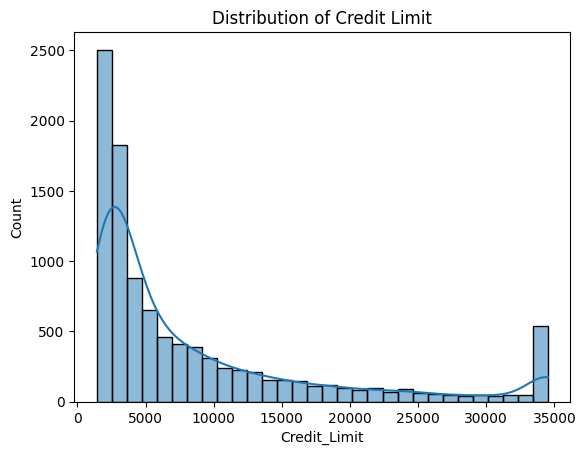

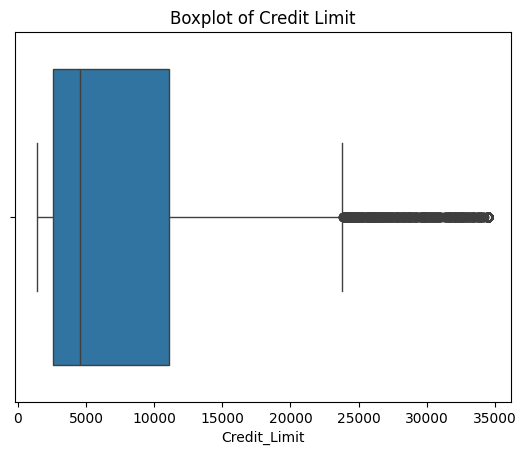

In [14]:
# Distribution of Credit_Limit
sns.histplot(df['Credit_Limit'], bins=30, kde=True)
plt.title("Distribution of Credit Limit")
plt.show()

sns.boxplot(x=df['Credit_Limit'])
plt.title("Boxplot of Credit Limit")
plt.show()

**Total transaction amount**

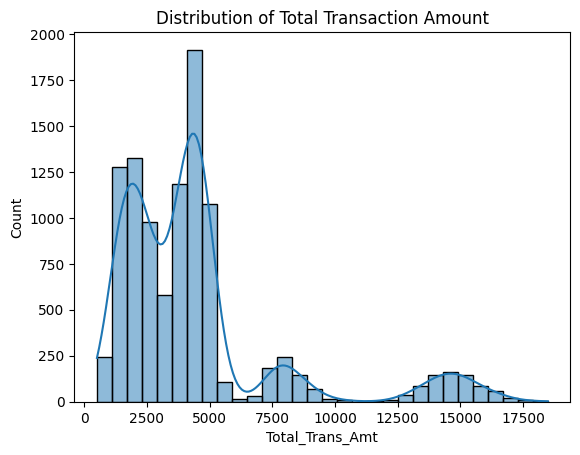

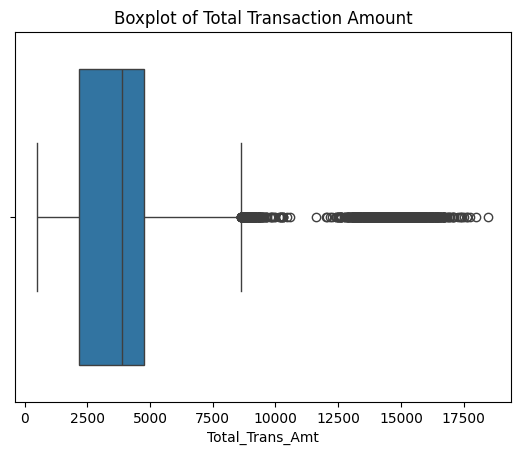

In [15]:
# Distribution of Total_Trans_Amt
sns.histplot(df['Total_Trans_Amt'], bins=30, kde=True)
plt.title("Distribution of Total Transaction Amount")
plt.show()

sns.boxplot(x=df['Total_Trans_Amt'])
plt.title("Boxplot of Total Transaction Amount")
plt.show()

**Total transaction count**

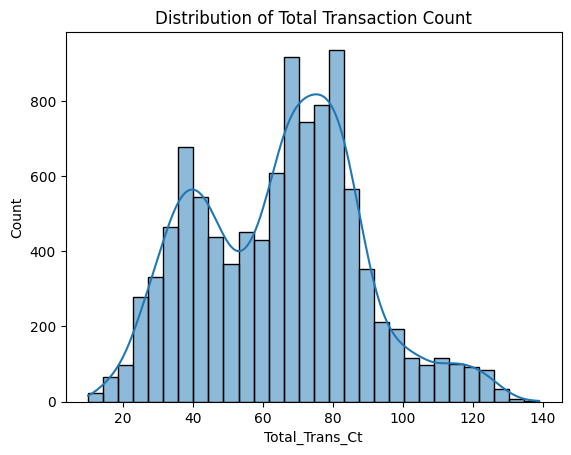

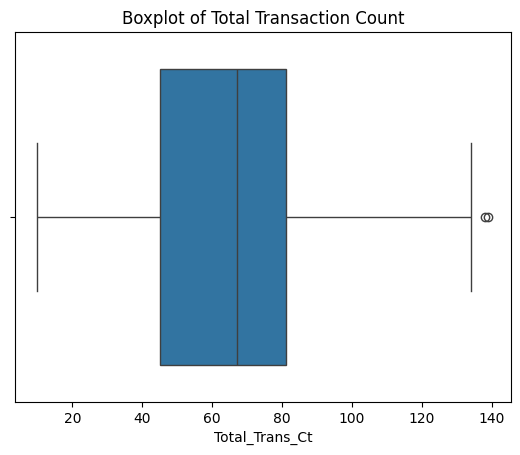

In [16]:
# Distribution of Total_Trans_Ct
sns.histplot(df['Total_Trans_Ct'], bins=30, kde=True)
plt.title("Distribution of Total Transaction Count")
plt.show()

sns.boxplot(x=df['Total_Trans_Ct'])
plt.title("Boxplot of Total Transaction Count")
plt.show()

**Average utilization ratio of customer**

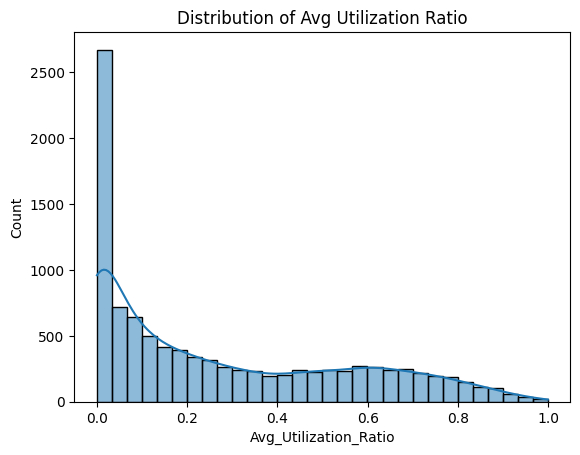

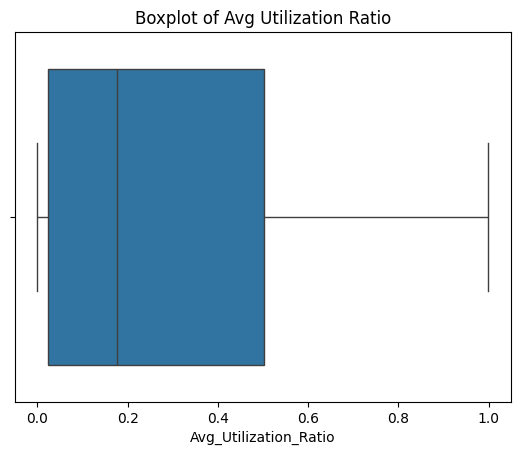

In [17]:
# Distribution of Avg_Utilization_Ratio
sns.histplot(df['Avg_Utilization_Ratio'], bins=30, kde=True)
plt.title("Distribution of Avg Utilization Ratio")
plt.show()

sns.boxplot(x=df['Avg_Utilization_Ratio'])
plt.title("Boxplot of Avg Utilization Ratio")
plt.show()

**Education level of customer**

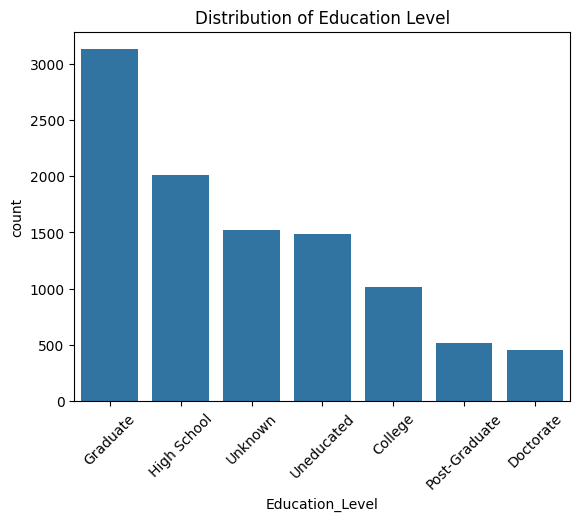

Education_Level
Graduate         30.887726
High School      19.877555
Unknown          14.999506
Uneducated       14.683519
College          10.002962
Post-Graduate     5.095290
Doctorate         4.453441
Name: proportion, dtype: float64


In [18]:
# Countplot for Education_Level
sns.countplot(x='Education_Level', data=df, order=df['Education_Level'].value_counts().index)
plt.title("Distribution of Education Level")
plt.xticks(rotation=45)
plt.show()

# Percentage distribution
print(df['Education_Level'].value_counts(normalize=True) * 100)

**Income category of customer.**

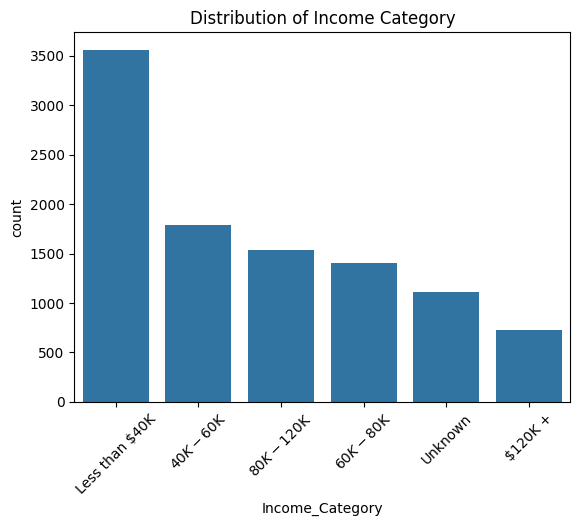

Income_Category
Less than $40K    35.163425
$40K - $60K       17.675521
$80K - $120K      15.157500
$60K - $80K       13.844179
Unknown           10.980547
$120K +            7.178829
Name: proportion, dtype: float64


In [19]:
# Countplot for Income_Category
sns.countplot(x='Income_Category', data=df, order=df['Income_Category'].value_counts().index)
plt.title("Distribution of Income Category")
plt.xticks(rotation=45)
plt.show()

# Percentage distribution
print(df['Income_Category'].value_counts(normalize=True) * 100)

**Type of card held by customer.**

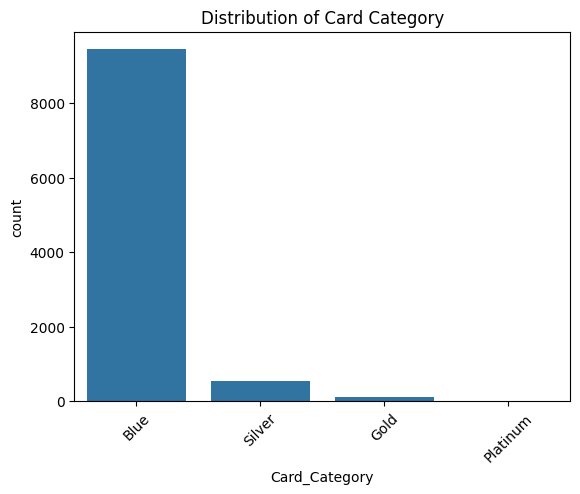

Card_Category
Blue        93.176656
Silver       5.480399
Gold         1.145453
Platinum     0.197492
Name: proportion, dtype: float64


In [20]:
# Countplot for Card_Category
sns.countplot(x='Card_Category', data=df, order=df['Card_Category'].value_counts().index)
plt.title("Distribution of Card Category")
plt.xticks(rotation=45)
plt.show()

# Percentage distribution
print(df['Card_Category'].value_counts(normalize=True) * 100)

**Correlation Heat Map for feature analysis**

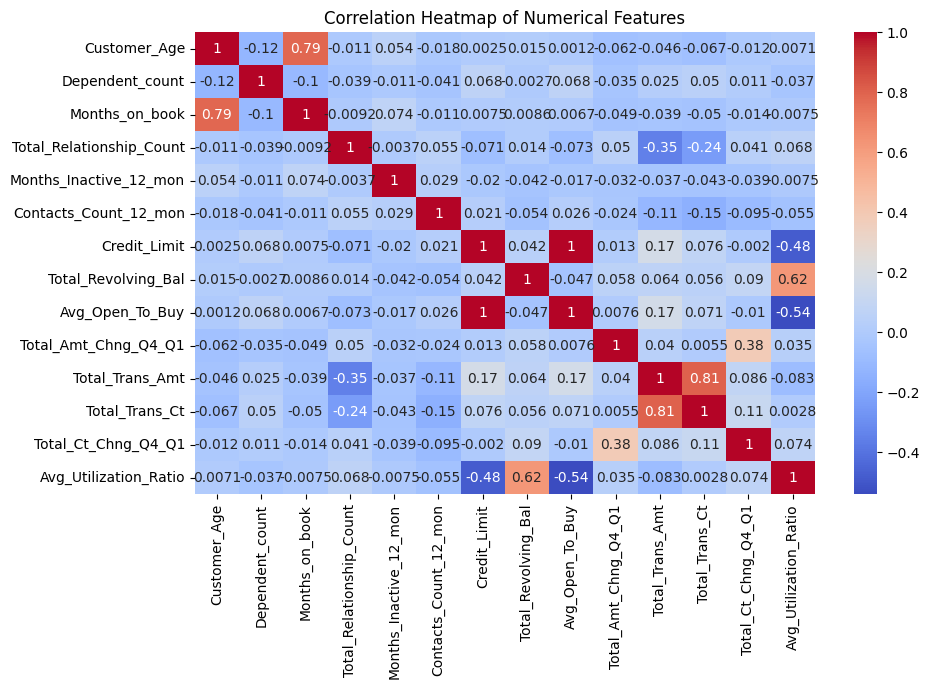

In [21]:
# Correlation heatmap
plt.figure(figsize=(10,6))
num_cols = df.select_dtypes(include=['number']).columns # Update num_cols to get current numerical columns
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

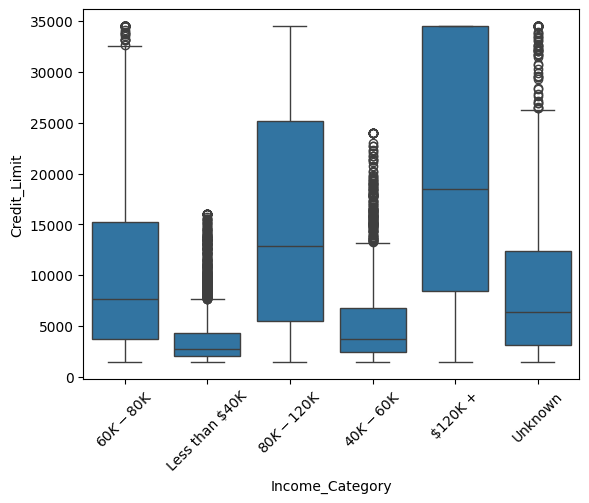

In [22]:
# Boxplot: Credit limit by income category
sns.boxplot(x='Income_Category', y='Credit_Limit', data=df)
plt.xticks(rotation=45)
plt.show()

**Adding the target column synthetically**

In [23]:
# Example rules for synthetic credit risk
df['Credit_Risk'] = np.where(
    (df['Avg_Utilization_Ratio'] > 0.8) |           # High utilization
    (df['Total_Revolving_Bal'] > 5000) |           # High revolving balance
    (df['Months_Inactive_12_mon'] > 6),            # Long inactivity
    1,  # High Risk => low credit score
    0   # Low Risk => high credit score
)

# Check distribution
print(df['Credit_Risk'].value_counts())



Credit_Risk
0    9660
1     467
Name: count, dtype: int64


**Leakage diagnostics** Before trusting any model, check (1) which clauses of the synthetic rule can fire at all, and (2) whether the features we remove can be rebuilt from the ones we keep.

In [25]:
clauses = {
    "Avg_Utilization_Ratio > 0.8": df.Avg_Utilization_Ratio > 0.8,
    "Total_Revolving_Bal > 5000": df.Total_Revolving_Bal > 5000,
    "Months_Inactive_12_mon > 6": df.Months_Inactive_12_mon > 6,
}
for k, v in clauses.items():
    print(f"{k:30s} fires for {int(v.sum()):5d} rows")
print("max Total_Revolving_Bal :", df.Total_Revolving_Bal.max())
print("max Months_Inactive     :", df.Months_Inactive_12_mon.max())
print("max |Credit_Limit - Revolving_Bal - Open_To_Buy|    :", float((df.Credit_Limit - df.Total_Revolving_Bal - df.Avg_Open_To_Buy).abs().max()))
print("max |Revolving_Bal / Credit_Limit - Utilization|    :", float((df.Total_Revolving_Bal / df.Credit_Limit - df.Avg_Utilization_Ratio).abs().max()))

Avg_Utilization_Ratio > 0.8    fires for   467 rows
Total_Revolving_Bal > 5000     fires for     0 rows
Months_Inactive_12_mon > 6     fires for     0 rows
max Total_Revolving_Bal : 2517
max Months_Inactive     : 6
max |Credit_Limit - Revolving_Bal - Open_To_Buy|    : 5.684341886080802e-14
max |Revolving_Bal / Credit_Limit - Utilization|    : 0.0005000000000000004


**How to read it:** if only the utilisation clause fires, the target is just `Avg_Utilization_Ratio > 0.8`. If the two identity checks are ~0, then `Avg_Open_To_Buy` + `Credit_Limit` rebuild `Total_Revolving_Bal` and utilisation, so dropping only the three target-defining columns is **not** enough. That is why the clean set (C) below also drops `Avg_Open_To_Buy`.

# ***`5. Privacy and Toxic Filter`***

**Objective**:
- Use **Presidio** to screen for and anonymize PII such as credit card numbers or device references.
- **Toxic-content filtering** (Detoxify) is part of the generic responsible-AI checklist, but it does not apply here: the dataset is purely tabular and has no free-text columns.

Because no text is present, no rows are expected to be dropped or modified.

**Note** This dataset has no free-text fields, and `CLIENTNUM` was already dropped in section 4 (data minimisation), so the Presidio guard below has nothing left to sanitise: it is a demonstration of the component, not a step the models depend on. Toxic-content filtering does not apply to tabular data. The cell is optional: skip it if Presidio / spaCy are not installed.

In [26]:
# OPTIONAL privacy step (Presidio PII screening). Safe to skip: nothing later depends on it.
# One-time install (terminal, or a notebook cell):
#   %pip install -q presidio-analyzer presidio-anonymizer spacy
#   !python -m spacy download en_core_web_lg        # or en_core_web_sm for a lighter install
SPACY_MODEL = "en_core_web_lg"

import re
try:
    from presidio_analyzer import AnalyzerEngine
    from presidio_analyzer.nlp_engine import NlpEngineProvider
    from presidio_analyzer.predefined_recognizers import CreditCardRecognizer
    from presidio_anonymizer import AnonymizerEngine
    PRESIDIO_OK = True
except ImportError:
    PRESIDIO_OK = False
    print("Presidio is not installed, skipping the optional privacy step (see the install lines above).")


class PrivacyGuard:
    """Redacts card numbers and numeric IDs with regex, then other PII (names, e-mails, phones, ...) with Presidio."""
    PATTERNS = {
        "CARD": r"\b(?:\d[ -]*?){13,16}\b",
        "CLIENTNUM": r"\b\d{6,12}\b",          # numeric client / account IDs
    }

    def __init__(self, spacy_model=SPACY_MODEL):
        nlp = NlpEngineProvider(nlp_configuration={
            "nlp_engine_name": "spacy",
            "models": [{"lang_code": "en", "model_name": spacy_model}],
        }).create_engine()
        self.analyzer = AnalyzerEngine(nlp_engine=nlp, supported_languages=["en"])
        self.analyzer.registry.add_recognizer(CreditCardRecognizer())
        self.anonymizer = AnonymizerEngine()

    def sanitize(self, text):
        if not isinstance(text, str) or not text.strip():
            return ""
        try:
            for pat in self.PATTERNS.values():
                text = re.sub(pat, "[REDACTED]", text, flags=re.IGNORECASE)
            results = self.analyzer.analyze(text=text, language="en")
            return self.anonymizer.anonymize(text, results).text
        except Exception as e:
            print(f"Sanitize error: {e}")
            return "[CONTENT REMOVED]"

    def sanitize_dataframe(self, df, columns, drop_original=True):
        """Use this on your own data: returns a copy with '<col>_sanitized' columns (raw columns dropped by default)."""
        out = df.copy()
        for col in columns:
            out[f"{col}_sanitized"] = out[col].astype(str).map(self.sanitize)
        return out.drop(columns=columns) if drop_original else out


if PRESIDIO_OK:
    try:
        guard = PrivacyGuard()
    except Exception as e:
        PRESIDIO_OK = False
        print("Presidio could not start (is the spaCy model installed?):", e)

if PRESIDIO_OK:
    # 1) Show that the guard works, on made-up text (NOT rows of the dataset)
    demo = "Client 712345678 paid with card 4111 1111 1111 1111. Contact: jane.doe@example.com"
    print("demo before:", demo)
    print("demo after :", guard.sanitize(demo))

    # 2) Apply it to the dataset only if identifier / free-text columns are still present
    PII_COLUMNS = [c for c in ["CLIENTNUM"] if c in df.columns]    # add your own text / ID columns here
    shape_before, cols_before = df.shape, list(df.columns)
    if PII_COLUMNS:
        df = guard.sanitize_dataframe(df, PII_COLUMNS)
        print(f"Sanitised columns {PII_COLUMNS}; raw columns dropped.")
    else:
        print("\nNo identifier or free-text columns are left in df (CLIENTNUM was already dropped in section 4),")
        print("so there is nothing to sanitise and the dataset is unchanged.")
        assert df.shape == shape_before and list(df.columns) == cols_before
        print("Dataset shape:", df.shape)

Presidio is not installed, skipping the optional privacy step (see the install lines above).


# ***`6. Experimenting with Models`***

**How this section is set up.** Early experiments trained on features that define the target, oversampled *before* splitting, and scaled outside a pipeline, which produced near-perfect but misleading scores. The final setup: (1) three explicit feature sets so the leakage is *measured*, (2) split first, (3) encoding, scaling and oversampling inside one `Pipeline` fitted on training data only, and (4) models judged by PR-AUC / recall / precision under 5-fold CV rather than accuracy.

## 6.1 Target, feature sets and train/test split (split first)

In [27]:
if "Credit_Risk" not in df.columns:   # normally created in the EDA section; recreate only if missing
    df["Credit_Risk"] = ((df.Avg_Utilization_Ratio > 0.8) | (df.Total_Revolving_Bal > 5000) | (df.Months_Inactive_12_mon > 6)).astype(int)
y = df["Credit_Risk"].copy()
df = df.drop(columns=["Credit_Risk"] + [c for c in df.columns if c.startswith("CLIENTNUM")])   # target + any leftover identifier
R["n_rows"], R["high_risk_n"], R["high_risk_rate"] = len(df), int(y.sum()), float(y.mean())
print(f"{R['n_rows']} customers, {R['high_risk_n']} high-risk ({R['high_risk_rate']:.1%})")

TARGET_DEFINING = ["Avg_Utilization_Ratio", "Total_Revolving_Bal", "Months_Inactive_12_mon"]
PROXY = ["Avg_Open_To_Buy"]
A, B, CLEAN = "A: all features (leaky)", "B: drop target-defining", "C: drop target-defining + proxy (clean)"
FEATURE_SETS = {
    A: list(df.columns),
    B: [c for c in df.columns if c not in TARGET_DEFINING],
    CLEAN: [c for c in df.columns if c not in TARGET_DEFINING + PROXY],
}
X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.3, stratify=y, random_state=SEED)
print("train:", X_train.shape, "test:", X_test.shape, "| high-risk in test:", int(y_test.sum()))

10127 customers, 467 high-risk (4.6%)
train: (7088, 17) test: (3039, 17) | high-risk in test: 140


## 6.2 Models: one leakage-safe pipeline, three feature sets, three models

In [28]:
CAT = ["Education_Level", "Income_Category", "Card_Category"]

def make_pipe(model, cols):
    cat = [c for c in CAT if c in cols]
    num = [c for c in cols if c not in cat]
    pre = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    ])
    # RandomOverSampler only runs when fitting, on the training part of each fold
    return Pipeline([("pre", pre), ("ros", RandomOverSampler(random_state=SEED)), ("clf", model)])

MODELS = {
    "KNN": lambda: KNeighborsClassifier(n_neighbors=5),
    "LogReg": lambda: LogisticRegression(max_iter=1000),
    "MLP": lambda: MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-4, batch_size=128,
                                 learning_rate="adaptive", max_iter=200, random_state=SEED),
}

### 6.3 5-fold cross-validation on the **training set only** (the test set stays untouched)

In [29]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "recall": "recall", "precision": "precision"}
rows = []
for fs, cols in FEATURE_SETS.items():
    for mn, mk in MODELS.items():
        r = cross_validate(make_pipe(mk(), cols), X_train[cols], y_train, cv=cv, scoring=scoring, n_jobs=-1)
        rows.append({"features": fs, "model": mn,
                     **{k: f"{r['test_'+k].mean():.3f} ± {r['test_'+k].std():.3f}" for k in scoring}})
cv_table = pd.DataFrame(rows)
R["cv_table"] = cv_table
display(cv_table)

,features,model,pr_auc,roc_auc,recall,precision
0,A: all features (leaky),KNN,0.373 ± 0.039,0.889 ± 0.026,0.707 ± 0.052,0.407 ± 0.029
1,A: all features (leaky),LogReg,0.997 ± 0.001,1.000 ± 0.000,1.000 ± 0.000,0.747 ± 0.017
2,A: all features (leaky),MLP,0.971 ± 0.011,0.998 ± 0.001,0.905 ± 0.044,0.900 ± 0.054
3,B: drop target-defining,KNN,0.058 ± 0.004,0.577 ± 0.020,0.214 ± 0.039,0.075 ± 0.013
4,B: drop target-defining,LogReg,0.942 ± 0.025,0.997 ± 0.001,1.000 ± 0.000,0.305 ± 0.016
5,B: drop target-defining,MLP,0.666 ± 0.035,0.968 ± 0.003,0.566 ± 0.021,0.642 ± 0.069
6,C: drop target-defining + proxy (clean),KNN,0.054 ± 0.003,0.554 ± 0.018,0.199 ± 0.037,0.067 ± 0.011
7,C: drop target-defining + proxy (clean),LogReg,0.104 ± 0.004,0.803 ± 0.009,0.957 ± 0.022,0.120 ± 0.004
8,C: drop target-defining + proxy (clean),MLP,0.104 ± 0.010,0.735 ± 0.005,0.089 ± 0.012,0.101 ± 0.018


### 6.4 Final fit on the training set, single evaluation on the held-out test set

In [30]:
fitted, test_rows = {}, []
for fs, cols in FEATURE_SETS.items():
    for mn, mk in MODELS.items():
        pipe = make_pipe(mk(), cols).fit(X_train[cols], y_train)
        fitted[(fs, mn)] = pipe
        p = pipe.predict_proba(X_test[cols])[:, 1]
        pred = (p >= 0.5).astype(int)
        test_rows.append({"features": fs, "model": mn, "accuracy": accuracy_score(y_test, pred),
                          "pr_auc": average_precision_score(y_test, p), "roc_auc": roc_auc_score(y_test, p),
                          "recall": recall_score(y_test, pred), "precision": precision_score(y_test, pred, zero_division=0)})
test_table = pd.DataFrame(test_rows).round(3)
R["test_table"] = test_table
display(test_table)

leaky = test_table[(test_table.features == A) & (test_table.model == "MLP")].iloc[0]
clean = test_table[(test_table.features == CLEAN) & (test_table.model == "MLP")].iloc[0]
R["acc_leaky"], R["acc_clean"] = float(leaky.accuracy), float(clean.accuracy)
R["prauc_leaky"], R["prauc_clean"] = float(leaky.pr_auc), float(clean.pr_auc)
R["recall_clean"], R["precision_clean"] = float(clean.recall), float(clean.precision)
print(f"MLP accuracy: leaky {R['acc_leaky']:.3f} -> clean {R['acc_clean']:.3f} | PR-AUC: leaky {R['prauc_leaky']:.3f} -> clean {R['prauc_clean']:.3f}")

,features,model,accuracy,pr_auc,roc_auc,recall,precision
0,A: all features (leaky),KNN,0.935,0.344,0.888,0.679,0.385
1,A: all features (leaky),LogReg,0.984,0.998,1.000,1.000,0.741
2,A: all features (leaky),MLP,0.992,0.975,0.999,0.943,0.886
3,B: drop target-defining,KNN,0.842,0.059,0.586,0.221,0.077
4,B: drop target-defining,LogReg,0.904,0.940,0.997,1.000,0.323
5,B: drop target-defining,MLP,0.968,0.649,0.976,0.521,0.702
6,C: drop target-defining + proxy (clean),KNN,0.834,0.054,0.558,0.200,0.067
7,C: drop target-defining + proxy (clean),LogReg,0.661,0.095,0.788,0.971,0.117
8,C: drop target-defining + proxy (clean),MLP,0.900,0.082,0.718,0.093,0.068


MLP accuracy: leaky 0.992 -> clean 0.900 | PR-AUC: leaky 0.975 -> clean 0.082


**Reading the results.** With all features (set A) the MLP looks excellent (accuracy 0.992, PR-AUC 0.975). Dropping only the three target-defining columns (set B) is not enough: logistic regression still reaches PR-AUC 0.940, because `Avg_Open_To_Buy = Credit_Limit − Total_Revolving_Bal` lets the model rebuild the target. Only the clean set C is honest: MLP PR-AUC 0.082 and ROC-AUC 0.718 against a base rate of 4.6% (about 1.8× chance); logistic regression is similar (PR-AUC 0.095, ROC-AUC 0.788). The MLP's accuracy of 0.900 is below the 0.954 of a model that always predicts "low risk", so accuracy is not a useful measure here. The earlier near-perfect scores were leakage, not model quality. The MLP is used in the rest of the notebook because the project is about risk controls for a neural network, not because it outperforms logistic regression.

# ***`7. Fairness and Bias: Demographic Parity and Equal Opportunity`***

**Goal**: for the clean MLP on the held-out test set, check whether the "high risk" flag is applied evenly across education and income groups.

1. **Demographic Parity**: the share of customers flagged "high risk" (flag rate) is the same across groups.
2. **Equal Opportunity**: among customers who truly are high-risk, the share correctly flagged (true-positive rate, TPR) is the same across groups.

For each attribute I show group sizes, flag rate, TPR and FPR, plus bootstrap confidence intervals for the gaps.

In [31]:
MODEL_FS, MODEL_NAME = CLEAN, "MLP"
pipe = fitted[(MODEL_FS, MODEL_NAME)]
cols = FEATURE_SETS[MODEL_FS]
p_test = pipe.predict_proba(X_test[cols])[:, 1]
pred_test = (p_test >= 0.5).astype(int)
MIN_POS = 10   # groups with fewer true high-risk cases give unreliable TPR

def group_table(attr):
    rows = []
    for g in sorted(X_test[attr].unique()):
        m = (X_test[attr] == g).values
        pos, neg = (y_test.values == 1) & m, (y_test.values == 0) & m
        rows.append({"group": g, "n": int(m.sum()), "n_high_risk": int(pos.sum()),
                     "flag_rate": pred_test[m].mean(),
                     "TPR": pred_test[pos].mean() if pos.sum() else np.nan,
                     "FPR": pred_test[neg].mean() if neg.sum() else np.nan})
    return pd.DataFrame(rows).set_index("group")

def gaps(tab):
    ok = tab[tab.n_high_risk >= MIN_POS]
    return tab.flag_rate.max() - tab.flag_rate.min(), (ok.TPR.max() - ok.TPR.min()) if len(ok) > 1 else np.nan

def bootstrap_gaps(attr, B=300):
    rng = np.random.RandomState(SEED)
    g_arr, y_arr = X_test[attr].values, y_test.values
    out = []
    for _ in range(B):
        i = rng.randint(0, len(y_arr), len(y_arr))
        rows = []
        for g in np.unique(g_arr[i]):
            m = g_arr[i] == g
            pos = m & (y_arr[i] == 1)
            rows.append((pred_test[i][m].mean(), pred_test[i][pos].mean() if pos.sum() >= MIN_POS else np.nan))
        r = np.array(rows)
        out.append((np.nanmax(r[:, 0]) - np.nanmin(r[:, 0]),
                    (np.nanmax(r[:, 1]) - np.nanmin(r[:, 1])) if np.isfinite(r[:, 1]).sum() > 1 else np.nan))
    return np.nanpercentile(np.array(out), [2.5, 97.5], axis=0)

R["fair"] = {}
for attr in ["Education_Level", "Income_Category"]:
    tab = group_table(attr)
    dp, eo = gaps(tab)
    ci = bootstrap_gaps(attr)
    R["fair"][attr] = {"dp_gap": float(dp), "eo_gap": float(eo), "dp_ci": ci[:, 0].tolist(), "eo_ci": ci[:, 1].tolist(),
                      "n_groups": int(len(tab)), "n_small": int((tab.n_high_risk < MIN_POS).sum()),
                      "worst_dp_group": tab.flag_rate.idxmax(), "best_dp_group": tab.flag_rate.idxmin()}
    print(f"\n=== {attr} (positive = flagged HIGH risk, an adverse outcome) ===")
    display(tab.round(3))
    print(f"Demographic-parity gap (flag rate): {dp:.3f}  95% bootstrap CI [{ci[0,0]:.3f}, {ci[1,0]:.3f}]")
    print(f"Equal-opportunity gap (TPR, groups with >= {MIN_POS} high-risk): {eo:.3f}  95% bootstrap CI [{ci[0,1]:.3f}, {ci[1,1]:.3f}]")


=== Education_Level (positive = flagged HIGH risk, an adverse outcome) ===


,n,n_high_risk,flag_rate,TPR,FPR
group,,,,,
College,290,14,0.072,0.143,0.069
Doctorate,126,5,0.079,0.200,0.074
Graduate,942,38,0.069,0.132,0.066
High School,621,35,0.050,0.057,0.049
Post-Graduate,168,8,0.048,0.000,0.050
Uneducated,441,21,0.054,0.048,0.055
Unknown,451,19,0.069,0.105,0.067


Demographic-parity gap (flag rate): 0.032  95% bootstrap CI [0.023, 0.094]
Equal-opportunity gap (TPR, groups with >= 10 high-risk): 0.095  95% bootstrap CI [0.071, 0.333]

=== Income_Category (positive = flagged HIGH risk, an adverse outcome) ===


,n,n_high_risk,flag_rate,TPR,FPR
group,,,,,
$120K +,189,0,0.011,NaN,0.011
$40K - $60K,572,32,0.079,0.094,0.078
$60K - $80K,440,15,0.032,0.200,0.026
$80K - $120K,431,8,0.019,0.000,0.019
Less than $40K,1070,78,0.099,0.090,0.100
Unknown,337,7,0.045,0.000,0.045


Demographic-parity gap (flag rate): 0.088  95% bootstrap CI [0.071, 0.109]
Equal-opportunity gap (TPR, groups with >= 10 high-risk): 0.110  95% bootstrap CI [0.027, 0.386]


**Reading fairness honestly:** high-risk cases are rare, so some groups have very few of them. Check `n_high_risk` before interpreting TPR gaps, and look at the bootstrap intervals; a gap whose interval is wide is not evidence either way. `Education_Level` and `Income_Category` are model inputs here, so also discuss whether they *should* be.

In [31]:
from IPython.display import Markdown
lines = ["**Fairness reading (auto-generated from the results above).**"]
for attr, d in R["fair"].items():
    eo_txt = "not computable (fewer than two groups with enough high-risk cases)" if np.isnan(d["eo_gap"]) else \
             f"{d['eo_gap']:.3f} (95% CI {d['eo_ci'][0]:.3f} to {d['eo_ci'][1]:.3f})"
    lines.append(f"* **{attr}**: flag rates differ by {d['dp_gap']:.3f} between '{d['best_dp_group']}' (lowest) and "
                 f"'{d['worst_dp_group']}' (highest); 95% CI of the gap {d['dp_ci'][0]:.3f} to {d['dp_ci'][1]:.3f}. "
                 f"Equal-opportunity (TPR) gap: {eo_txt}. {d['n_small']} of {d['n_groups']} groups have fewer than {MIN_POS} "
                 f"true high-risk cases, so their TPR is excluded or unreliable.")
lines.append("* A max-minus-min gap is never negative, so its interval cannot 'include zero'; judge size and width, not significance.")
lines.append("* `Education_Level` and `Income_Category` are model inputs. If the gaps are material, the first mitigation to test is removing them.")
display(Markdown("\n".join(lines)))

**Fairness reading (auto-generated from the results above).**
* **Education_Level**: flag rates differ by 0.032 between 'Post-Graduate' (lowest) and 'Doctorate' (highest); 95% CI of the gap 0.023 to 0.094. Equal-opportunity (TPR) gap: 0.095 (95% CI 0.071 to 0.333). 2 of 7 groups have fewer than 10 true high-risk cases, so their TPR is excluded or unreliable.
* **Income_Category**: flag rates differ by 0.088 between '$120K +' (lowest) and 'Less than $40K' (highest); 95% CI of the gap 0.071 to 0.109. Equal-opportunity (TPR) gap: 0.110 (95% CI 0.027 to 0.386). 3 of 6 groups have fewer than 10 true high-risk cases, so their TPR is excluded or unreliable.
* A max-minus-min gap is never negative, so its interval cannot 'include zero'; judge size and width, not significance.
* `Education_Level` and `Income_Category` are model inputs. If the gaps are material, the first mitigation to test is removing them.

**Interpretation.** `Education_Level`: flag rates range only from 4.8% to 7.9%, and true high-risk rates are similar across groups (4.0%–5.6%), so there is no clear disparity. `Income_Category`: flag rates fall steadily with income (9.9% for "Less than 40K" down to 1.1% for "120K +"), and so do the true high-risk rates (7.3% down to 0%), so the demographic-parity gap largely reflects real differences between groups, not a model-only effect. That is still a fairness concern, because income and education are model inputs, and removing them is the first mitigation to test. Equal-opportunity gaps are not reliable: the clean MLP flags few true high-risk cases, so each group's TPR rests on only 0–7 correctly flagged cases, and the bootstrap intervals are very wide.

# ***`8. Explainability - SHAP and LIME`***

**Goal**:
*  **SHAP**: global and local feature attributions for the clean MLP.
*  **LIME**: local explanations for three case types (true positive, false negative, true negative), cross-checked against SHAP.

100%|██████████| 150/150 [00:01<00:00, 80.98it/s]


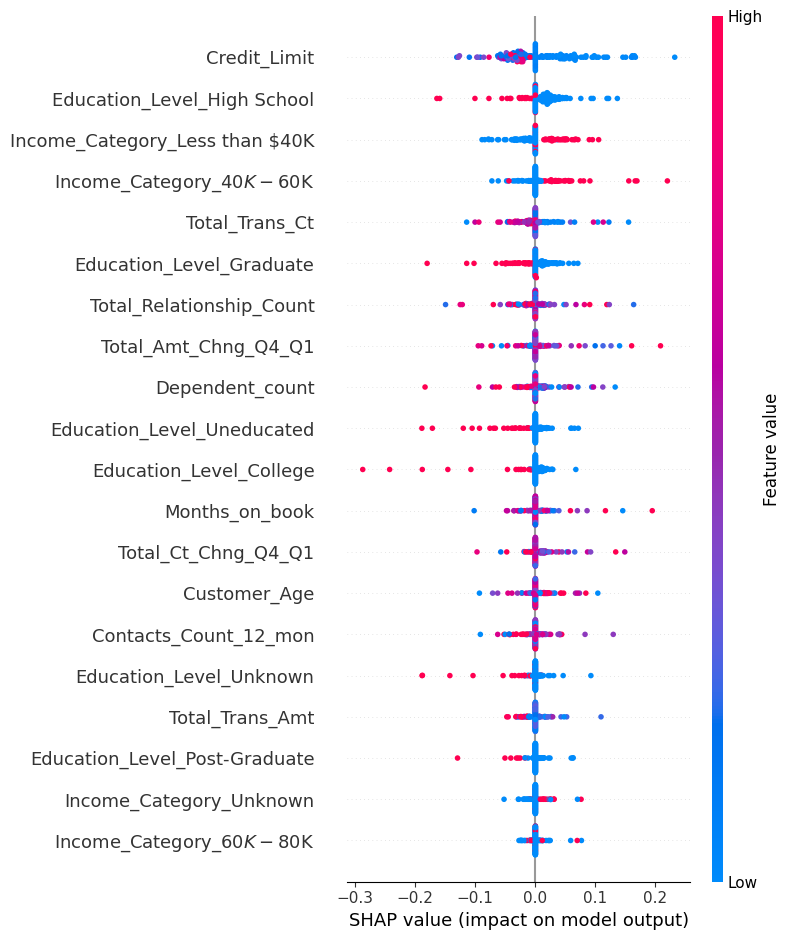

,mean |SHAP|
Credit_Limit,0.047121
Education_Level_High School,0.024483
Income_Category_Less than $40K,0.021562
Income_Category_$40K - $60K,0.016985
Total_Trans_Ct,0.016821
Education_Level_Graduate,0.016049
Total_Relationship_Count,0.015576
Total_Amt_Chng_Q4_Q1,0.014268
Dependent_count,0.014098
Education_Level_Uneducated,0.012760


In [32]:
import shap
from lime.lime_tabular import LimeTabularExplainer

pre, clf = pipe.named_steps["pre"], pipe.named_steps["clf"]
Xtr_t, Xte_t = pre.transform(X_train[cols]), pre.transform(X_test[cols])
names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
f = lambda A_: clf.predict_proba(A_)[:, 1]

bg = shap.sample(Xtr_t, 100, random_state=SEED)
idx = np.random.RandomState(SEED).choice(len(Xte_t), 150, replace=False)
sv = shap.KernelExplainer(f, bg).shap_values(Xte_t[idx], nsamples=200)
shap.summary_plot(sv, Xte_t[idx], feature_names=names, show=False)
plt.tight_layout(); plt.show()

imp = pd.Series(np.abs(sv).mean(0), index=names).sort_values(ascending=False)
R["top_shap"] = imp.head(5).round(4).to_dict()
display(imp.head(10).to_frame("mean |SHAP|"))

In [33]:
lime_exp = LimeTabularExplainer(Xtr_t, feature_names=names, class_names=["Low risk", "High risk"],
                                mode="classification", discretize_continuous=True, random_state=SEED)
yt, pt = y_test.values, (f(Xte_t) >= 0.5).astype(int)
cases = {"true_positive": (1, 1), "false_negative": (1, 0), "true_negative": (0, 0)}
R["lime_top"] = {}
for cname, (a, b) in cases.items():
    ids = np.where((yt == a) & (pt == b))[0]
    if len(ids) == 0:
        print(f"{cname}: no such case in the test set"); continue
    e = lime_exp.explain_instance(Xte_t[ids[0]], clf.predict_proba, num_features=6, num_samples=2000)
    R["lime_top"][cname] = [(k, round(v, 3)) for k, v in e.as_list()[:3]]
    print(f"\n{cname} (test row {ids[0]}), P(high risk) = {f(Xte_t[ids[:1]])[0]:.3f}")
    for k, v in e.as_list():
        print(f"   {v:+.3f}  {k}")


true_positive (test row 182), P(high risk) = 0.997
   +0.091  Credit_Limit <= -0.67
   -0.059  Income_Category_$40K - $60K <= 0.00
   -0.040  Total_Trans_Amt > 0.10
   -0.032  Income_Category_Less than $40K <= 0.00
   +0.030  Months_on_book <= -0.61
   -0.025  0.00 < Education_Level_Graduate <= 1.00

false_negative (test row 1), P(high risk) = 0.004
   +0.052  0.00 < Income_Category_Less than $40K <= 1.00
   +0.045  Education_Level_Uneducated <= 0.00
   +0.043  Total_Trans_Ct <= -0.84
   -0.041  Income_Category_$40K - $60K <= 0.00
   +0.039  Income_Category_$120K + <= 0.00
   -0.038  0.00 < Education_Level_Graduate <= 1.00

true_negative (test row 0), P(high risk) = 0.000
   -0.403  Card_Category_Platinum <= 0.00
   -0.078  Credit_Limit > 0.27
   -0.072  Income_Category_Less than $40K <= 0.00
   -0.050  Income_Category_$40K - $60K <= 0.00
   -0.046  Education_Level_College > 0.00
   +0.043  Education_Level_Uneducated <= 0.00


**Cross-check:** do SHAP's top global features (table above) also show up in LIME's local explanations? Where they disagree, say so in the model card. Explanations describe the model, not causality, and `Avg_Open_To_Buy` / `Total_Revolving_Bal` should no longer appear because they are not model inputs in set C.

In [34]:
lines = ["**SHAP vs LIME cross-check (auto-generated).**",
         "* Top global SHAP features: " + ", ".join(f"`{k}` ({v})" for k, v in R["top_shap"].items())]
top_set = set(R["top_shap"].keys())
for cname, items in R["lime_top"].items():
    feats = [k for k, _ in items]
    hit = [k for k in feats if any(t in k for t in top_set)]
    lines.append(f"* LIME {cname}: top local conditions {feats}; {len(hit)} of 3 mention a top-5 SHAP feature.")
leak = [n for n in R["top_shap"] if n in ("Avg_Open_To_Buy", "Total_Revolving_Bal", "Avg_Utilization_Ratio", "Months_Inactive_12_mon")]
lines.append("* Leakage features in SHAP top 5: " + (", ".join(leak) if leak else "none (as expected for feature set C)."))
display(Markdown("\n".join(lines)))

**SHAP vs LIME cross-check (auto-generated).**
* Top global SHAP features: `Credit_Limit` (0.0471), `Education_Level_High School` (0.0245), `Income_Category_Less than $40K` (0.0216), `Income_Category_$40K - $60K` (0.017), `Total_Trans_Ct` (0.0168)
* LIME true_positive: top local conditions ['Credit_Limit <= -0.67', 'Income_Category_$40K - $60K <= 0.00', 'Total_Trans_Amt > 0.10']; 2 of 3 mention a top-5 SHAP feature.
* LIME false_negative: top local conditions ['0.00 < Income_Category_Less than $40K <= 1.00', 'Education_Level_Uneducated <= 0.00', 'Total_Trans_Ct <= -0.84']; 2 of 3 mention a top-5 SHAP feature.
* LIME true_negative: top local conditions ['Card_Category_Platinum <= 0.00', 'Credit_Limit > 0.27', 'Income_Category_Less than $40K <= 0.00']; 2 of 3 mention a top-5 SHAP feature.
* Leakage features in SHAP top 5: none (as expected for feature set C).

**Interpretation.** `Credit_Limit` is the clearest global driver (mean |SHAP| 0.047, about twice the next feature). Three of the top five SHAP features are education or income categories, and none of the leakage features appear, as expected for feature set C. LIME agrees only partly: in each of the three cases, 2 of the top 3 local conditions involve a top-5 SHAP feature. For the true positive, a low (scaled) `Credit_Limit` is the strongest push towards high risk (+0.091). For the true negative, `Card_Category_Platinum` dominates (-0.403) although it is not a top-5 SHAP feature. For the false negative, the individual weights are small (at most 0.052) and the final P(high risk) is 0.004, so the explanation says little about why the case was missed. SHAP here uses 150 test rows and 200 samples, and LIME is a local surrogate, so disagreement is a prompt to look further, not an error. Neither method shows causality.

# ***`9. Risk Controls for Neural Network (MLP) Model`***

**Goal**
Minimize model errors, bias, and overfitting while ensuring ethical and reliable credit risk predictions.

**1. Data Risks**

*  Leakage Prevention: Remove the features that define the target (`Avg_Utilization_Ratio`, `Total_Revolving_Bal`, `Months_Inactive_12_mon`) **and** the proxy `Avg_Open_To_Buy` (= `Credit_Limit` − `Total_Revolving_Bal`). Measured effect: MLP accuracy 0.992 → 0.900 and PR-AUC 0.975 → 0.082.

*  Missing Data: Impute or encode missing values carefully, especially for sensitive attributes ("Unknown" education and income are kept as their own category).

*  Outliers: Check and treat extreme values that may skew predictions.

**2. Model Risks**

*  Overfitting:

      *  Use regularization (alpha parameter).

      *  Limit hidden layer sizes or epochs if needed.

      *  Tune and compare models with 5-fold CV on the training set; use the held-out test set once.

*  Instability: Neural nets can be sensitive to initialization; set random_state for reproducibility.

*  Metric choice: at 4.6% prevalence accuracy is misleading (always predicting "low risk" scores 0.954); report PR-AUC, recall and precision.

**3. Bias & Fairness**

*   Ensure predictions don’t unfairly penalize protected groups. Gender and marital status were removed; education and income remain model inputs and are checked.

*   Evaluate subgroup metrics (flag rate, TPR, FPR) together with group sizes and bootstrap intervals.

**4. Operational Controls**

*  Monitoring: Track model performance, flag rate and fairness gaps over time for drift.

*  Explainability: Use feature importance or SHAP values to interpret decisions.

*  Human Oversight: High-risk decisions should be reviewed by credit officers.

# ***`10. Comprehensive Risk Analysis and Management Plan`***

Risk register for the credit-risk MLP. The last column links each risk to the results measured in this notebook.

| Risk | What can go wrong | Potential impact | Mitigation strategy | Evidence from this project |
|---|---|---|---|---|
| **Data Privacy** | Exposure of personal information (credit limits, card category, age, income band, education) | Regulatory fines, loss of trust | Data minimisation, **anonymisation**, **differential privacy**, secure storage; Presidio for PII masking | `CLIENTNUM`, gender and marital status were dropped. The data has no free text, and the optional Presidio step was skipped in this run because it was not installed. |
| **Model Bias / Discrimination** | Prediction disparities across education and income groups | Unfair lending, regulatory action | **Fairness checks** (demographic parity, equal opportunity) with group sizes and bootstrap intervals; test removing education and income; fairness-constrained models; monitor gaps after deployment | Education: DP gap 0.032 (95% CI 0.023–0.094), EO gap 0.095 (CI 0.071–0.333). Income: DP gap 0.088 (CI 0.071–0.109), EO gap 0.110 (CI 0.027–0.386). 2 of 7 education groups and 3 of 6 income groups have fewer than 10 high-risk cases (the top income band has none), so EO gaps are unreliable. 3 of the top 5 SHAP features are education or income categories. The income flag-rate gap partly follows real label-rate differences (7.3% high-risk in the lowest band, 0% in the top band). |
| **Data Quality** | Missing, incorrect or inconsistent features; inputs outside the training range | Model inaccuracy, misclassification of risk | **Data validation pipelines**, careful imputation, input range checks, monitoring of feature distributions | "Unknown" education and income are kept as a category. Scaling a single input by 0.5× or 2× flips 4.0–6.7% of decisions. |
| **Overfitting / Target Leakage** | Features that define or rebuild the target inflate scores; accuracy hides weak signal | Increased defaults or missed risks; false confidence | Audit features against the target definition before training, split **before** resampling, put all preprocessing in a pipeline, **cross-validate** and evaluate once on a held-out test set, report PR-AUC / recall / precision | All features: MLP accuracy 0.992, PR-AUC 0.975. Dropping only the three target-defining features still leaves logistic regression at PR-AUC 0.940, because `Avg_Open_To_Buy` rebuilds the target. Clean set C: accuracy 0.900, PR-AUC 0.082, recall 0.093, precision 0.068. That is about 1.8× the 4.6% base rate, and accuracy is below the 0.954 of always predicting "low risk". |
| **Interpretability & Explainability** | Black-box model reduces trust and transparency | Regulatory non-compliance, poor stakeholder adoption | **SHAP** for global and local attribution, **LIME** for local explanations, cross-checked against each other | No leakage feature appears in the SHAP top 5. SHAP and LIME agree only partly (2 of 3 top local conditions match a top-5 SHAP feature in each case). Explanations are approximations, not causal. |
| **Synthetic Target Creation** | The synthetic label does not reflect true customer risk | Misleading business decisions | Validate the synthetic rule, adjust thresholds, label the model clearly as synthetic and for internal demonstration only, replace with real default outcomes | Only the utilisation clause fires (467 rows, 4.6%); the revolving-balance (>5000) and inactivity (>6) clauses never fire. The label is effectively `Avg_Utilization_Ratio > 0.8`. |
| **Adversarial Robustness** | Manipulated inputs at prediction time; poisoned training labels | Wrong credit decisions, degraded model | Input range validation, audits of training labels, drift monitoring on the flag rate, adversarial testing | Clean model: `Credit_Limit` has the largest effect (10.9% flagged at 0.5×, 1.8% at 2×); largest decision flips 6.7% (`Total_Trans_Amt` 2×). Flipping 5% / 10% of training labels lowers PR-AUC from 0.082 to 0.064 / 0.062 and raises recall (0.093 → 0.164 / 0.264) mainly because more customers get flagged. The label-filtering defence (0.067 / 0.069) is not clearly better (single run). Targeted poisoning and backdoors were not tested. |
| **Operational Risk** | Errors in deployment or integration | Business disruption, incorrect credit decisions | **CI/CD pipelines with monitoring**, alerting and rollback mechanisms | Not tested in this notebook; listed as a requirement for any real deployment. |

# ***`11. Model Card`***

The model card below is generated by cell 12c from the computed results and is copied here.

## Model card: MLP credit-risk classifier (synthetic label)

**Model:** scikit-learn MLPClassifier (64, 32), ReLU, Adam; preprocessing and random over-sampling inside one pipeline fitted on training data only.

**Data:** Kaggle BankChurners, 10,127 customers; synthetic target `Credit_Risk` (high risk = 467, 4.6%) defined by a rule on utilisation, revolving balance and inactivity. Identifiers, gender and marital status removed.

**Intended use:** demonstration of a responsible-AI workflow, **not** for real lending decisions.

**Leakage audit:** with all features the MLP reached accuracy 0.992 (PR-AUC 0.975); after removing the three target-defining features and the proxy `Avg_Open_To_Buy`, accuracy is 0.900 (PR-AUC 0.082, recall 0.093, precision 0.068) on a held-out test set.

**Fairness (clean model, held-out test set):** Education_Level demographic-parity gap 0.032 (95% CI 0.023-0.094), equal-opportunity gap 0.095 (95% CI 0.071-0.333); Income_Category demographic-parity gap 0.088 (95% CI 0.071-0.109), equal-opportunity gap 0.110 (95% CI 0.027-0.386). Groups with few high-risk cases make TPR gaps unreliable.

**Explainability:** top SHAP features: `Credit_Limit`, `Education_Level_High School`, `Income_Category_Less than $40K`, `Income_Category_$40K - $60K`, `Total_Trans_Ct`. LIME local explanations were computed for a true positive, a false negative and a true negative; top local conditions are listed in the cross-check in section 8.

**Robustness:** worst single-feature perturbation (Credit_Limit x0.5) moved PR-AUC from 0.082 to 0.071. Label-flip poisoning: PR-AUC 0.082 (clean) -> 0.064 (5% flipped) -> 0.062 (10% flipped); with the filtering defence 0.067 and 0.069.

**Limitations:** the label is a rule on the inputs, not real default data; one dataset; fairness only on education and income; random (not adversarial) poisoning; explanations are approximations, not causal.

# ***`12. Red Team - Attacks Playbook`***

**Feature Attack**

### 12a. Feature manipulation: perturb raw inputs at prediction time (the pipeline re-scales correctly)

In [35]:
def perturb(pipe_, cols_, feat, mult):
    Xa = X_test[cols_].copy(); Xa[feat] = Xa[feat] * mult
    return pipe_.predict_proba(Xa)[:, 1]

rows = []
base = pipe.predict_proba(X_test[cols])[:, 1]
for feat in ["Credit_Limit", "Total_Trans_Amt", "Total_Trans_Ct"]:
    for mult in (0.5, 2.0):
        pa = perturb(pipe, cols, feat, mult)
        rows.append({"model": "clean (C)", "feature": feat, "x": mult, "pr_auc": average_precision_score(y_test, pa),
                     "flag_rate": (pa >= .5).mean(), "flip_rate": ((pa >= .5) != (base >= .5)).mean()})
leaky_pipe, leaky_cols = fitted[(A, "MLP")], FEATURE_SETS[A]
bl = leaky_pipe.predict_proba(X_test[leaky_cols])[:, 1]
for mult in (0.5, 2.0):
    pa = perturb(leaky_pipe, leaky_cols, "Total_Revolving_Bal", mult)
    rows.append({"model": "leaky (A)", "feature": "Total_Revolving_Bal", "x": mult, "pr_auc": average_precision_score(y_test, pa),
                 "flag_rate": (pa >= .5).mean(), "flip_rate": ((pa >= .5) != (bl >= .5)).mean()})
attack_table = pd.DataFrame(rows).round(3)
R["attack_table"] = attack_table
R["base_prauc"] = float(average_precision_score(y_test, base))
display(attack_table)

,model,feature,x,pr_auc,flag_rate,flip_rate
0,clean (C),Credit_Limit,0.5,0.071,0.109,0.047
1,clean (C),Credit_Limit,2.0,0.089,0.018,0.045
2,clean (C),Total_Trans_Amt,0.5,0.076,0.048,0.040
3,clean (C),Total_Trans_Amt,2.0,0.092,0.046,0.067
4,clean (C),Total_Trans_Ct,0.5,0.078,0.069,0.062
5,clean (C),Total_Trans_Ct,2.0,0.083,0.016,0.066
6,leaky (A),Total_Revolving_Bal,0.5,0.955,0.045,0.005
7,leaky (A),Total_Revolving_Bal,2.0,0.968,0.033,0.017


**Feature attack — inference.** Perturbing inputs flipped at most 6.7% of the clean model's decisions (`Total_Trans_Amt` ×2). `Credit_Limit` changed the flag rate most (10.9% flagged at ×0.5, 1.8% at ×2), consistent with it being the top SHAP feature. `Total_Trans_Amt` is not in the SHAP top 5; doubling a feature pushes values outside the training range, where an MLP extrapolates, and SHAP was estimated on 150 rows, so treat this as a lead to check, not a finding. Because the clean model is only slightly better than chance, PR-AUC changes of ±0.01 are within noise.

For the leaky model (set A), scaling `Total_Revolving_Bal` by ×0.5 or ×2 changed PR-AUC only from 0.975 to 0.955 / 0.968 and flipped just 0.5% / 1.7% of decisions. That is not robustness: `Avg_Utilization_Ratio` and `Avg_Open_To_Buy` still carry the same information about the target, so changing one input barely matters.

**Data Poisoning**

### 12b. Data poisoning: flip training labels only, evaluate on the clean test set; then a defence

In [36]:
def eval_model(model_pipe):
    p = model_pipe.predict_proba(X_test[cols])[:, 1]
    return {"pr_auc": average_precision_score(y_test, p), "recall": recall_score(y_test, p >= .5),
            "precision": precision_score(y_test, p >= .5, zero_division=0)}

rng = np.random.RandomState(SEED)
rows = [{"scenario": "clean training data", **eval_model(pipe)}]
for frac in (0.05, 0.10):
    y_pois = np.array(y_train.values, copy=True)
    flip = rng.choice(len(y_pois), int(frac * len(y_pois)), replace=False)
    y_pois[flip] = 1 - y_pois[flip]
    m_p = make_pipe(MODELS["MLP"](), cols).fit(X_train[cols], y_pois)
    rows.append({"scenario": f"poisoned: {int(frac*100)}% labels flipped", **eval_model(m_p)})

    # defence: drop the 10% of rows whose label agrees least with out-of-fold predictions, retrain
    oof = cross_val_predict(make_pipe(LogisticRegression(max_iter=1000), cols), X_train[cols], y_pois,
                            cv=cv, method="predict_proba")[:, 1]
    agree = np.where(y_pois == 1, oof, 1 - oof)
    keep = agree > np.quantile(agree, 0.10)
    m_d = make_pipe(MODELS["MLP"](), cols).fit(X_train[cols][keep], y_pois[keep])
    rows.append({"scenario": f"  + defence (drop 10% lowest agreement), {int(frac*100)}% flipped", **eval_model(m_d)})
poison_table = pd.DataFrame(rows).round(3)
R["poison_table"] = poison_table
display(poison_table)

,scenario,pr_auc,recall,precision
0,clean training data,0.082,0.093,0.068
1,poisoned: 5% labels flipped,0.064,0.164,0.073
2,"+ defence (drop 10% lowest agreement), 5% fl...",0.067,0.157,0.066
3,poisoned: 10% labels flipped,0.062,0.264,0.064
4,"+ defence (drop 10% lowest agreement), 10% f...",0.069,0.300,0.068


**Data poisoning — inference.** Flipping 5% or 10% of training labels lowered PR-AUC from 0.082 to 0.064 and 0.062 and raised recall (0.093 → 0.164 → 0.264) while precision stayed near the base rate, because most flips turn "low risk" into "high risk" and the model flags more customers. The simple filtering defence gave no clear difference (0.067 and 0.069). This is a single run on 140 test positives. The defence assumes random, minority noise and would not catch targeted or clustered poisoning or backdoor triggers.

**Key takeaways.** 

(1) Accuracy misleads at 4.6% prevalence; the always-"low risk" baseline is 0.954. 

(2) The near-perfect first results were target leakage, found by feature-set ablation. 

(3) Without leakage the model is only modestly better than chance. 

(4) Income and education categories make up 3 of the top 5 SHAP features and track the group differences, so they need review before any real use. 

(5) All numbers describe how well the model re-learns a synthetic rule, not real credit risk.

**12c. Generate the model card text** (run this last; the output is the text copied into section 11)

In [37]:
from IPython.display import Markdown
fa, fi = R["fair"]["Education_Level"], R["fair"]["Income_Category"]
pz = R["poison_table"].reset_index(drop=True)
fmt_eo = lambda d: "n/a" if np.isnan(d["eo_gap"]) else f"{d['eo_gap']:.3f} (95% CI {d['eo_ci'][0]:.3f}-{d['eo_ci'][1]:.3f})"
worst = R["attack_table"][R["attack_table"].model == "clean (C)"].sort_values("pr_auc").iloc[0]
card = f'''
## Model card: MLP credit-risk classifier (synthetic label)

**Model:** scikit-learn MLPClassifier (64, 32), ReLU, Adam; preprocessing and random over-sampling inside one pipeline fitted on training data only.
**Data:** Kaggle BankChurners, {R["n_rows"]:,} customers; synthetic target `Credit_Risk` (high risk = {R["high_risk_n"]:,}, {R["high_risk_rate"]:.1%}) defined by a rule on utilisation, revolving balance and inactivity. Identifiers, gender and marital status removed.
**Intended use:** demonstration of a responsible-AI workflow, **not** for real lending decisions.

**Leakage audit:** with all features the MLP reached accuracy {R["acc_leaky"]:.3f} (PR-AUC {R["prauc_leaky"]:.3f}); after removing the three target-defining features and the proxy `Avg_Open_To_Buy`, accuracy is {R["acc_clean"]:.3f} (PR-AUC {R["prauc_clean"]:.3f}, recall {R["recall_clean"]:.3f}, precision {R["precision_clean"]:.3f}) on a held-out test set.

**Fairness (clean model, held-out test set):** Education_Level demographic-parity gap {fa["dp_gap"]:.3f} (95% CI {fa["dp_ci"][0]:.3f}-{fa["dp_ci"][1]:.3f}), equal-opportunity gap {fmt_eo(fa)}; Income_Category demographic-parity gap {fi["dp_gap"]:.3f} (95% CI {fi["dp_ci"][0]:.3f}-{fi["dp_ci"][1]:.3f}), equal-opportunity gap {fmt_eo(fi)}. Groups with few high-risk cases make TPR gaps unreliable.

**Explainability:** top SHAP features: {", ".join(f"`{k}`" for k in R["top_shap"])}. LIME local explanations were computed for a true positive, a false negative and a true negative; top local conditions are listed in the cross-check in section 8.

**Robustness:** worst single-feature perturbation ({worst.feature} x{worst.x}) moved PR-AUC from {R["base_prauc"]:.3f} to {worst.pr_auc:.3f}. Label-flip poisoning: PR-AUC {pz.iloc[0].pr_auc:.3f} (clean) -> {pz.iloc[1].pr_auc:.3f} (5% flipped) -> {pz.iloc[3].pr_auc:.3f} (10% flipped); with the filtering defence {pz.iloc[2].pr_auc:.3f} and {pz.iloc[4].pr_auc:.3f}.

**Limitations:** the label is a rule on the inputs, not real default data; one dataset; fairness only on education and income; random (not adversarial) poisoning; explanations are approximations, not causal.
'''
R["model_card"] = card
display(Markdown(card))


## Model card: MLP credit-risk classifier (synthetic label)

**Model:** scikit-learn MLPClassifier (64, 32), ReLU, Adam; preprocessing and random over-sampling inside one pipeline fitted on training data only.
**Data:** Kaggle BankChurners, 10,127 customers; synthetic target `Credit_Risk` (high risk = 467, 4.6%) defined by a rule on utilisation, revolving balance and inactivity. Identifiers, gender and marital status removed.
**Intended use:** demonstration of a responsible-AI workflow, **not** for real lending decisions.

**Leakage audit:** with all features the MLP reached accuracy 0.992 (PR-AUC 0.975); after removing the three target-defining features and the proxy `Avg_Open_To_Buy`, accuracy is 0.900 (PR-AUC 0.082, recall 0.093, precision 0.068) on a held-out test set.

**Fairness (clean model, held-out test set):** Education_Level demographic-parity gap 0.032 (95% CI 0.023-0.094), equal-opportunity gap 0.095 (95% CI 0.071-0.333); Income_Category demographic-parity gap 0.088 (95% CI 0.071-0.109), equal-opportunity gap 0.110 (95% CI 0.027-0.386). Groups with few high-risk cases make TPR gaps unreliable.

**Explainability:** top SHAP features: `Credit_Limit`, `Education_Level_High School`, `Income_Category_Less than $40K`, `Income_Category_$40K - $60K`, `Total_Trans_Ct`. LIME local explanations were computed for a true positive, a false negative and a true negative; top local conditions are listed in the cross-check in section 8.

**Robustness:** worst single-feature perturbation (Credit_Limit x0.5) moved PR-AUC from 0.082 to 0.071. Label-flip poisoning: PR-AUC 0.082 (clean) -> 0.064 (5% flipped) -> 0.062 (10% flipped); with the filtering defence 0.067 and 0.069.

**Limitations:** the label is a rule on the inputs, not real default data; one dataset; fairness only on education and income; random (not adversarial) poisoning; explanations are approximations, not causal.


# ***`13. Embedding XAI in the Risk Modeling Lifecycle`***

**1) Development Stage (Ante-Hoc)**

Use:


*   Exploratory analyses of data distributions, correlations, and potential biases (EDA).

*   Prefer intrinsically interpretable models (logistic regression, monotonic gradient boosting) as baselines → “XAI by design.”

XAI Role: Early debugging, sanity-checking, feature transparency.

Target Audience:


*   Developers/Data Scientists → need interpretability for debugging.
*   Compliance Officers → early evidence of fairness and bias checks.

Methods: Coefficients (logistic regression), monotonicity constraints, feature constraints.

**2) Model Evaluation & Validation (Post-Hoc)**

Use:


*   Apply SHAP/LIME to analyze influence of single factors, especially in large deviations/residuals (misclassified risky borrowers).
*   Detect (un)fairness: check contributions of sensitive features (Education_Level, Income_Category).

*   Benchmark multiple XAI methods to avoid blind spots.

XAI Role: Evidence and justification for model outputs, detection of weaknesses.

Target Audience:

*  Operators → explanations for monitoring decisions.

*  Authorities/Regulators → post-hoc bias assessment.

Methods: SHAP (global + local), LIME, counterfactual explanations.

**3) Deployment & Operations**

Use:

*  Provide human-understandable summaries for credit officers or customers (e.g., “Your high risk score is mainly due to low income and many missed payments”).

*  Add confidence intervals or uncertainty flags → highlight cases model is not designed to use.

XAI Role: Justification of single decisions, monitoring fairness drift.

Target Audience:

*  End-Users / Affected Parties → need simple, meaningful, and understandable explanations.

*  Operators/Helpdesk → need actionable insights for escalation.

Methods: Local SHAP force plots, rule-based surrogate models, textual explanations.

**4) Auditing & Monitoring**

Use:

*  Continuous post-hoc explanations to detect concept drift and fairness degradation.

*  Document boundaries of XAI:

    * Explanations are approximations.

    * Not causal → can’t infer “if income increased by X, default risk drops by Y” unless causal model.

XAI Role: Central component of an AI audit (traceability, fairness, robustness).

Target Audience:

*  Auditors/Regulators → need systematic fairness reports.

*  Management → assurance that the system is compliant and trustworthy.

Methods: Residual analysis + explanation trends, fairness dashboards, explanation benchmarking.


**Key Principles to Follow**

*  Evidence for decisions → every model output must have a traceable justification.

*  Audience-tailored explanations → different detail for developers vs. end-users.

*  Identify out-of-scope cases → flagging inputs outside training distribution.

*  Balance → combine ante-hoc interpretability (intrinsic models) with post-hoc explainability (debugging + fairness).


**Boundaries & Caveats**

*  XAI explains model boundaries, not reality → risk of misleading interpretations.

*  Approximations may fail for high-dimensional nonlinear models.

*  Explanations are subjective: what looks “fair” to one group may not to another.

**Note on earlier results.** An earlier run of this notebook trained on features that define the target, oversampled before the split, and evaluated fairness on a different, unscaled split, so its near-perfect accuracy and zero fairness gaps were artefacts. The current version measures the leakage explicitly (feature sets A/B/C), splits first, evaluates fairness on the same fitted model and test set, adds SHAP, and uses training-only poisoning. The target is still a synthetic rule on the inputs: metrics show how well the model approximates that rule, not real credit risk.